# 作业 3：NumPy、Matplotlib 与 pandas
学号：20244080119
姓名：李奕昕
环境：py_exp

### 任务 0：环境记录
记录当前 Conda 环境、学号、机器指纹、RUN_ID 和 Python 版本。

In [1]:
import hashlib
import os
import platform
import sys
import uuid

STUDENT_ID = 20244080119
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "未检测到 CONDA_DEFAULT_ENV")
machine_info = (
    f"{platform.node()}|{platform.machine()}|"
    f"{platform.system()}|{uuid.getnode()}"
)
MACHINE_FP = hashlib.sha256(machine_info.encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[Conda 环境] {CONDA_ENV}")
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[Python 版本] {platform.python_version()}")
print(f"[Python 解释器] {sys.executable}")

[Conda 环境] py_exp
[学号] 20244080119
[机器指纹] 60bb97c2c4e89b33
[RUN_ID] 20244080119-60bb97c2c4e89b33
[Python 版本] 3.11.17
[Python 解释器] d:\Anaconda\envs\py_exp\python.exe


### 任务 1.1：计算半圆密度
在区间 [-2, 2] 内使用半圆密度公式计算；区间外返回 0.0。

In [2]:
import numpy as np

def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    return 0.0

test_values = [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0]
for value in test_values:
    result = wigner_density(value)
    print(f"f({value}) = {result:.6f}, return type={type(result).__name__}")

f(-3.0) = 0.000000, return type=float
f(-2.0) = 0.000000, return type=float
f(-1.0) = 0.275664, return type=float
f(0.0) = 0.318310, return type=float
f(1.0) = 0.275664, return type=float
f(2.0) = 0.000000, return type=float
f(3.0) = 0.000000, return type=float


### 任务 1.2：生成 Wigner 矩阵
对矩阵上三角部分（含对角线）独立采样，采样分布为均值 0、方差 1/n 的正态分布，再对称填充。

In [3]:
import numpy as np

def generate_wigner(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    matrix = np.empty((n, n), dtype=float)
    standard_deviation = np.sqrt(1.0 / n)
    for i in range(n):
        for j in range(i, n):
            value = np.random.normal(loc=0.0, scale=standard_deviation)
            matrix[i, j] = value
            matrix[j, i] = value
    return matrix

np.random.seed(2026)
test_matrix = generate_wigner(4)
print("生成的 4×4 Wigner 矩阵:")
print(test_matrix)
print(f"矩阵形状: {test_matrix.shape}")
print(f"矩阵是否对称: {np.allclose(test_matrix, test_matrix.T)}")

for invalid_n in [0, -2, 2.5, True]:
    try:
        generate_wigner(invalid_n)
    except (TypeError, ValueError) as error:
        print(f"输入 {invalid_n!r}: {type(error).__name__}: {error}")

生成的 4×4 Wigner 矩阵:
[[-0.21585926 -0.69643698  0.15578533 -0.00661744]
 [-0.69643698  0.72485386  0.14907637 -0.41494802]
 [ 0.15578533  0.14907637 -0.79807926  0.3067189 ]
 [-0.00661744 -0.41494802  0.3067189  -0.15879856]]
矩阵形状: (4, 4)
矩阵是否对称: True
输入 0: ValueError: n 必须是正整数
输入 -2: ValueError: n 必须是正整数
输入 2.5: TypeError: n 必须是整数
输入 True: TypeError: n 必须是整数


### 任务 1.3：计算并排序特征值
Wigner 矩阵是对称矩阵，使用 NumPy 的对称矩阵特征值算法计算并返回升序排列的特征值。

In [4]:
import numpy as np

def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(matrix))

test_matrix = np.array([[2.0, 1.0], [1.0, 2.0]])
spectrum = get_spectrum(test_matrix)

print("测试矩阵:")
print(test_matrix)
print(f"排序后的特征值: {spectrum}")
print(f"是否按非递减顺序排列: {bool(np.all(spectrum[:-1] <= spectrum[1:]))}")

测试矩阵:
[[2. 1.]
 [1. 2.]]
排序后的特征值: [1. 3.]
是否按非递减顺序排列: True


### 任务 1.4：比较特征值分布与半圆密度
分别生成阶数为 100、200、500、1000 的 Wigner 矩阵，将特征值标准化直方图与半圆密度曲线比较。固定随机种子以便复现。

n=100: 特征值数量=100, 最小值=-1.937, 最大值=2.051
n=200: 特征值数量=200, 最小值=-1.960, 最大值=1.944
n=500: 特征值数量=500, 最小值=-1.968, 最大值=2.002
n=1000: 特征值数量=1000, 最小值=-1.979, 最大值=1.961


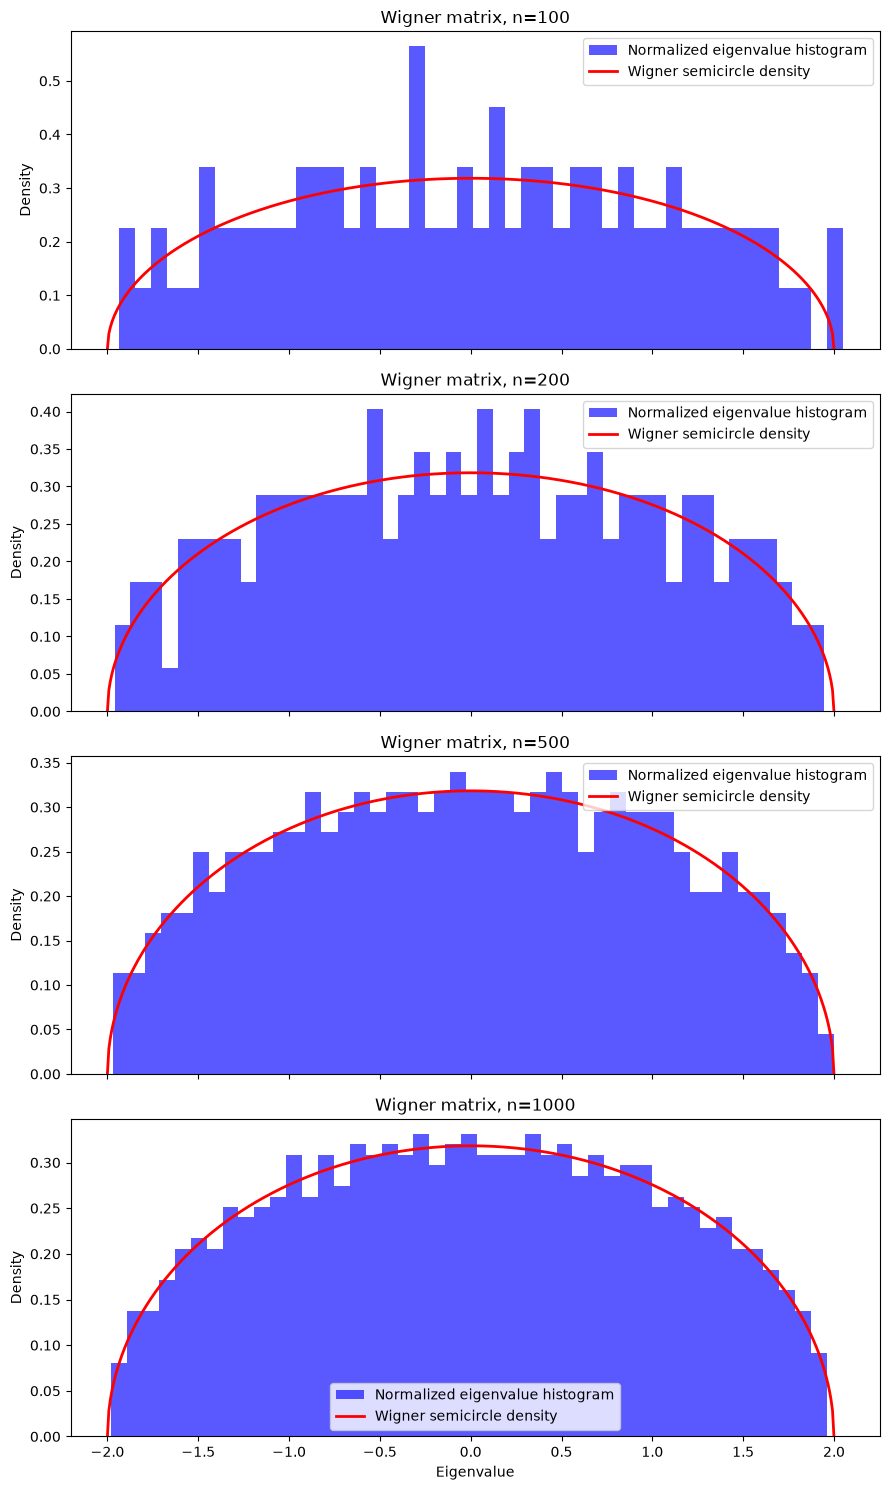

In [5]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(2026)
sample_sizes = [100, 200, 500, 1000]
x_values = np.linspace(-2, 2, 500)
density_values = np.array([wigner_density(x) for x in x_values])

fig, axes = plt.subplots(4, 1, figsize=(9, 15), sharex=True)
for axis, n in zip(axes, sample_sizes):
    matrix = generate_wigner(n)
    eigenvalues = get_spectrum(matrix)
    axis.hist(
        eigenvalues,
        bins=45,
        density=True,
        color="blue",
        alpha=0.65,
        label="Normalized eigenvalue histogram",
    )
    axis.plot(
        x_values,
        density_values,
        color="red",
        linewidth=2,
        label="Wigner semicircle density",
    )
    axis.set_title(f"Wigner matrix, n={n}")
    axis.set_ylabel("Density")
    axis.legend()
    print(
        f"n={n}: 特征值数量={len(eigenvalues)}, "
        f"最小值={eigenvalues.min():.3f}, 最大值={eigenvalues.max():.3f}"
    )

axes[-1].set_xlabel("Eigenvalue")
plt.tight_layout()
plt.show()

根据图形观察，n 大约达到 500 时，特征值直方图通常已能较好地贴合半圆密度曲线；n=1000 时拟合一般会更稳定。有限样本下的拟合效果会受随机抽样影响。

### 任务 2.1：验证生命游戏棋盘
有效棋盘必须是 NumPy ndarray、二维，并且所有元素只能为 0 或 1。函数返回 Python bool。

In [6]:
import numpy as np

def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())

valid_board = np.array([[0, 1, 0], [1, 1, 0]])
invalid_value_board = np.array([[0, 2], [1, 0]])
one_dimensional_board = np.array([0, 1, 0])
test_boards = [valid_board, invalid_value_board, one_dimensional_board, [[0, 1], [1, 0]]]

for board in test_boards:
    result = is_valid_board(board)
    print(
        f"棋盘类型={type(board).__name__}, 有效={result}, "
        f"返回类型={type(result).__name__}"
    )

棋盘类型=ndarray, 有效=True, 返回类型=bool
棋盘类型=ndarray, 有效=False, 返回类型=bool
棋盘类型=ndarray, 有效=False, 返回类型=bool
棋盘类型=list, 有效=False, 返回类型=bool


### 任务 2.2：计算生命游戏的下一步
先验证棋盘，再使用原棋盘的状态统计八个邻居。边界通过首尾环绕处理，整个新棋盘同时计算。

In [7]:
import numpy as np

def gol_step(board):
    if not isinstance(board, np.ndarray):
        raise TypeError("board 必须是 NumPy ndarray")
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的二维数组")

    neighbor_count = np.zeros(board.shape, dtype=int)
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if row_shift == 0 and col_shift == 0:
                continue
            neighbor_count += np.roll(
                board,
                shift=(row_shift, col_shift),
                axis=(0, 1),
            )

    alive = board == 1
    next_board = (
        (alive & ((neighbor_count == 2) | (neighbor_count == 3)))
        | (~alive & (neighbor_count == 3))
    ).astype(int)
    return next_board

blinker = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0],
])
next_blinker = gol_step(blinker)

print("当前棋盘:")
print(blinker)
print("\n下一步棋盘:")
print(next_blinker)
print(f"输入形状: {blinker.shape}, 输出形状: {next_blinker.shape}")
print(f"下一步活细胞数: {int(next_blinker.sum())}")

try:
    gol_step(np.array([[0, 2], [1, 0]]))
except (TypeError, ValueError) as error:
    print(f"无效棋盘测试: {type(error).__name__}: {error}")

当前棋盘:
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]

下一步棋盘:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
输入形状: (5, 5), 输出形状: (5, 5)
下一步活细胞数: 3
无效棋盘测试: ValueError: board 必须是只包含 0 和 1 的二维数组


### 任务 2.3：绘制生命游戏棋盘
活细胞显示为黑色，死细胞显示为白色；隐藏网格线、坐标轴标签和刻度。

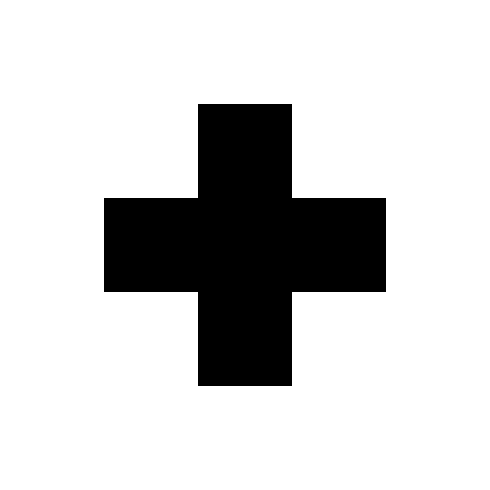

棋盘形状: (5, 5)
活细胞数量: 5


In [8]:
import matplotlib.pyplot as plt
import numpy as np

def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的二维 NumPy 数组")

    fig, axis = plt.subplots(figsize=(5, 5))
    axis.imshow(
        board,
        cmap=plt.get_cmap("gray_r"),
        vmin=0,
        vmax=1,
        interpolation="none",
    )
    axis.set_axis_off()
    plt.tight_layout()
    plt.show()
    print(f"棋盘形状: {board.shape}")
    print(f"活细胞数量: {int(board.sum())}")

board_to_draw = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0],
])
draw_gol_board(board_to_draw)

### 任务 3.1：读取并检查 Iris 数据
Iris.csv 包含 Id、Species 和四项测量列。Id 保留为普通列，DataFrame 使用默认的 0–149 行索引，因此 iloc[34] 和 iloc[37] 分别对应第 35 行和第 38 行。列名中 Sepal 表示萼片，Petal 表示花瓣，Length 和 Width 分别表示长度和宽度；Species 是花卉种类。

In [9]:
import pandas as pd

iris_data = pd.read_csv("Iris.csv")

COLUMN_MAP = {
    "sepal_length": "SepalLengthCm",
    "sepal_width": "SepalWidthCm",
    "petal_length": "PetalLengthCm",
    "petal_width": "PetalWidthCm",
}
SPECIES_COLUMN = "Species"

print(f"数据点数量: {len(iris_data)}")
print(f"列名: {iris_data.columns.tolist()}")
print("每列数据类型:")
print(iris_data.dtypes)
print(f"花卉种类数量: {iris_data[SPECIES_COLUMN].nunique()}")
print(f"花卉种类: {iris_data[SPECIES_COLUMN].unique().tolist()}")
print("\n字段映射:")
print(f"花卉种类: {SPECIES_COLUMN}")
print(f"萼片长度: {COLUMN_MAP['sepal_length']}")
print(f"萼片宽度: {COLUMN_MAP['sepal_width']}")
print(f"花瓣长度: {COLUMN_MAP['petal_length']}")
print(f"花瓣宽度: {COLUMN_MAP['petal_width']}")

数据点数量: 150
列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
每列数据类型:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
花卉种类数量: 3
花卉种类: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

字段映射:
花卉种类: Species
萼片长度: SepalLengthCm
萼片宽度: SepalWidthCm
花瓣长度: PetalLengthCm
花瓣宽度: PetalWidthCm


### 任务 3.2：更正指定的两行数据
数据行从 0 开始计数，第 35 行对应位置 34，第 38 行对应位置 37。按字段名修改测量值，并将花卉种类设为 setosa。

In [10]:
iris_corrected = iris_data.copy()
if len(iris_corrected) < 38:
    raise ValueError("iris.csv 至少需要包含 38 行数据")

measurement_columns = [
    COLUMN_MAP["sepal_length"],
    COLUMN_MAP["sepal_width"],
    COLUMN_MAP["petal_length"],
    COLUMN_MAP["petal_width"],
]
corrections = {
    34: [4.9, 3.1, 1.5, 0.2],
    37: [4.9, 3.6, 1.4, 0.1],
}

for row_position, measurements in corrections.items():
    for column, value in zip(measurement_columns, measurements):
        column_position = iris_corrected.columns.get_loc(column)
        iris_corrected.iloc[row_position, column_position] = value
    species_position = iris_corrected.columns.get_loc(SPECIES_COLUMN)
    iris_corrected.iloc[row_position, species_position] = "Iris-setosa"

print("更正后的第 35 行:")
print(iris_corrected.iloc[34])
print("\n更正后的第 38 行:")
print(iris_corrected.iloc[37])

更正后的第 35 行:
Id                        35
SepalLengthCm            4.9
SepalWidthCm             3.1
PetalLengthCm            1.5
PetalWidthCm             0.2
Species          Iris-setosa
Name: 34, dtype: object

更正后的第 38 行:
Id                        38
SepalLengthCm            4.9
SepalWidthCm             3.6
PetalLengthCm            1.4
PetalWidthCm             0.1
Species          Iris-setosa
Name: 37, dtype: object


### 任务 3.3：新增花瓣和萼片比例列
分别用花瓣长度除以花瓣宽度、萼片长度除以萼片宽度，新增 Petal.Ratio 和 Sepal.Ratio 两列。

In [11]:
iris_corrected["Petal.Ratio"] = (
    iris_corrected[COLUMN_MAP["petal_length"]]
    / iris_corrected[COLUMN_MAP["petal_width"]]
)
iris_corrected["Sepal.Ratio"] = (
    iris_corrected[COLUMN_MAP["sepal_length"]]
    / iris_corrected[COLUMN_MAP["sepal_width"]]
)

print("新增比例列后的前 5 行:")
print(
    iris_corrected[
        [
            COLUMN_MAP["petal_length"],
            COLUMN_MAP["petal_width"],
            "Petal.Ratio",
            COLUMN_MAP["sepal_length"],
            COLUMN_MAP["sepal_width"],
            "Sepal.Ratio",
        ]
    ].head()
)
print(f"\nDataFrame 形状: {iris_corrected.shape}")

新增比例列后的前 5 行:
   PetalLengthCm  PetalWidthCm  Petal.Ratio  SepalLengthCm  SepalWidthCm  \
0            1.4           0.2          7.0            5.1           3.5   
1            1.4           0.2          7.0            4.9           3.0   
2            1.3           0.2          6.5            4.7           3.2   
3            1.5           0.2          7.5            4.6           3.1   
4            1.4           0.2          7.0            5.0           3.6   

   Sepal.Ratio  
0     1.457143  
1     1.633333  
2     1.468750  
3     1.483871  
4     1.388889  

DataFrame 形状: (150, 8)


### 任务 3.4：保存更正并扩展后的数据
将 DataFrame 保存为 iris_corrected.csv，保存到 iris.csv 所在目录，并打印路径确认。

In [12]:
from pathlib import Path

source_path = Path("Iris.csv").resolve()
output_path = source_path.with_name("iris_corrected.csv")
iris_corrected.to_csv(output_path, index=False)

print(f"输出文件路径: {output_path}")
print(f"文件已创建: {output_path.exists()}")
print(f"保存的数据行数: {len(iris_corrected)}")

输出文件路径: D:\python_course\EXP_hw_homework\iris_corrected.csv
文件已创建: True
保存的数据行数: 150


### 任务 3.5：按花卉种类汇总比例统计量
一次 groupby 和 agg 操作，计算每种花的花瓣比例及萼片比例的均值、中位数、最小值、最大值和标准差。

In [13]:
ratio_summary = iris_corrected.groupby(SPECIES_COLUMN).agg({
    "Petal.Ratio": ["mean", "median", "min", "max", "std"],
    "Sepal.Ratio": ["mean", "median", "min", "max", "std"],
})

print("各花卉种类的比例统计结果:")
print(ratio_summary)
print(f"\n汇总的花卉种类数量: {len(ratio_summary)}")

各花卉种类的比例统计结果:
                Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
Iris-versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
Iris-virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                         
                   median       min       max       std  
Species                                                  
Iris-setosa      1.463063  1.268293  1.956522  0.118750  
Iris-versicolor  2.161290  1.764706  2.818182  0.228658  
Iris-virginica   2.169540  1.823529  2.961538  0.246992  

汇总的花卉种类数量: 3
